# FDS Case Study 1: EastWest Airlines Customer Clustering

## 1. Introduction
Customer segmentation groups customers with similar characteristics. In this case study, clustering algorithms are applied to the EastWest Airlines dataset to explore patterns in airline customer behaviour.

## 2. Objectives
- Inspect and prepare the airline customer dataset.
- Explore feature distributions and correlations.
- Apply K-Means, Agglomerative Clustering, and DBSCAN.
- Visualize clusters using Principal Component Analysis (PCA).
- Compare clustering results using cluster counts and silhouette scores.

## 3. Dataset
The workbook `EastWestAirlines.xlsx` contains airline customer data. The `ID#` field identifies customers and should not be used as a clustering feature. The code below loads the worksheet named `data`.

## 4. Libraries and methods
Pandas and NumPy are used for data handling; Matplotlib and Seaborn for visualizations; and Scikit-learn for scaling, clustering, PCA, and evaluation.

## 5. Workflow
Load data → inspect and clean → explore → scale features → cluster → visualize → compare → conclude.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

print("Libraries imported successfully")



Libraries imported successfully


## Upload the dataset

- Run the next cell and select `EastWestAirlines.xlsx` from your computer. The workbook must be uploaded to the current Colab session before loading it.

In [ ]:
from google.colab import files
uploaded = files.upload()
print("Uploaded files:", list(uploaded.keys()))

## Load the customer data

- Load the `data` worksheet. Check the displayed sheet name and shape. The customer records should be loaded, not a worksheet that only describes the workbook.

In [ ]:
file_path = '/content/EastWestAirlines.xlsx'

df = pd.read_excel(file_path, sheet_name='data')

print("Dataset shape:", df.shape)
print(df.head())
print(df.info())

Dataset shape: (3999, 12)
   ID#  Balance  Qual_miles  cc1_miles  cc2_miles  cc3_miles  Bonus_miles  \
0    1    28143           0          1          1          1          174   
1    2    19244           0          1          1          1          215   
2    3    41354           0          1          1          1         4123   
3    4    14776           0          1          1          1          500   
4    5    97752           0          4          1          1        43300   

   Bonus_trans  Flight_miles_12mo  Flight_trans_12  Days_since_enroll  Award?  
0            1                  0                0               7000       0  
1            2                  0                0               6968       0  
2            4                  0                0               7034       0  
3            1                  0                0               6952       0  
4           26               2077                4               6935       1  
<class 'pandas.core.frame.DataF

## Inspect the dataset

- Review column types, missing values, and descriptive statistics before preprocessing.

In [ ]:
print("Missing values:")
print(df.isnull().sum())

print("\nStatistical summary:")
print(df.describe())

Missing values:
ID#                  0
Balance              0
Qual_miles           0
cc1_miles            0
cc2_miles            0
cc3_miles            0
Bonus_miles          0
Bonus_trans          0
Flight_miles_12mo    0
Flight_trans_12      0
Days_since_enroll    0
Award?               0
dtype: int64

Statistical summary:
               ID#       Balance    Qual_miles    cc1_miles    cc2_miles  \
count  3999.000000  3.999000e+03   3999.000000  3999.000000  3999.000000   
mean   2014.819455  7.360133e+04    144.114529     2.059515     1.014504   
std    1160.764358  1.007757e+05    773.663804     1.376919     0.147650   
min       1.000000  0.000000e+00      0.000000     1.000000     1.000000   
25%    1010.500000  1.852750e+04      0.000000     1.000000     1.000000   
50%    2016.000000  4.309700e+04      0.000000     1.000000     1.000000   
75%    3020.500000  9.240400e+04      0.000000     3.000000     1.000000   
max    4021.000000  1.704838e+06  11148.000000     5.000000     3

## Clean and prepare features

- Remove the customer identifier, replace infinite values, and fill missing numeric values using each column's median.

In [ ]:
data = df.drop(columns=['ID#']).copy()

data = data.replace([np.inf, -np.inf], np.nan)
data = data.fillna(data.median())

print("Data shape after removing ID:", data.shape)
print(data.head())

Data shape after removing ID: (3999, 11)
   Balance  Qual_miles  cc1_miles  cc2_miles  cc3_miles  Bonus_miles  \
0    28143           0          1          1          1          174   
1    19244           0          1          1          1          215   
2    41354           0          1          1          1         4123   
3    14776           0          1          1          1          500   
4    97752           0          4          1          1        43300   

   Bonus_trans  Flight_miles_12mo  Flight_trans_12  Days_since_enroll  Award?  
0            1                  0                0               7000       0  
1            2                  0                0               6968       0  
2            4                  0                0               7034       0  
3            1                  0                0               6952       0  
4           26               2077                4               6935       1  


## Explore feature distributions

- Histograms help show the distribution of the numerical customer attributes.

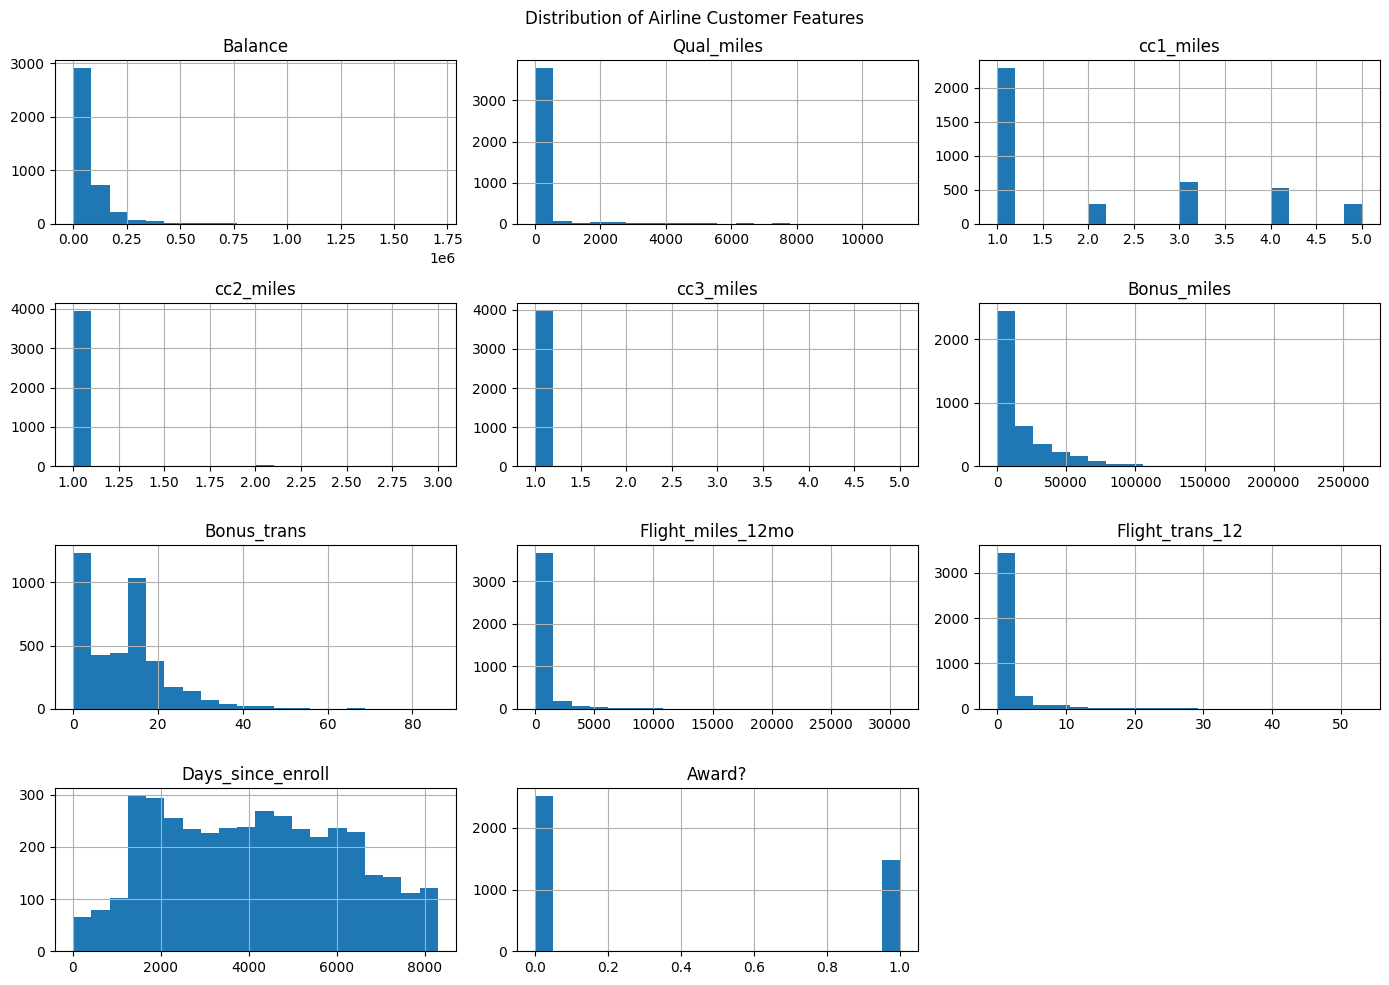

In [ ]:
data.hist(figsize=(14, 10), bins=20)
plt.suptitle("Distribution of Airline Customer Features")
plt.tight_layout()
plt.show()

## Examine correlations

- The heatmap shows correlations among numerical features. Correlation does not necessarily imply causation.

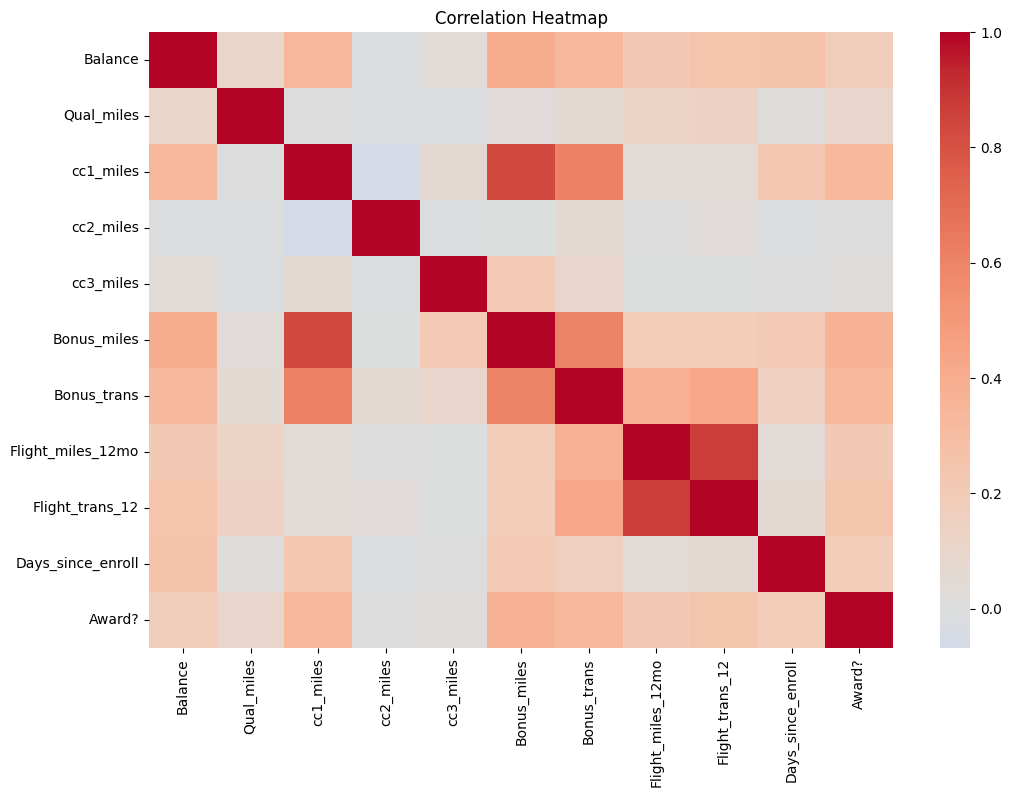

In [ ]:
plt.figure(figsize=(12, 8))
sns.heatmap(data.corr(), cmap='coolwarm', center=0)
plt.title("Correlation Heatmap")
plt.show()

## Standardize features

- Standardization puts numerical features on comparable scales, which is important for distance-based clustering.

In [ ]:
scaler = StandardScaler()
X = scaler.fit_transform(data)

print("Standardization completed")
print("Number of customers:", X.shape[0])
print("Number of features:", X.shape[1])

Standardization completed
Number of customers: 3999
Number of features: 11


## Select K with the Elbow Method

- Compare inertia across K values. Choose a plausible number of clusters based on the bend in the curve; the elbow is a guide rather than a guarantee.

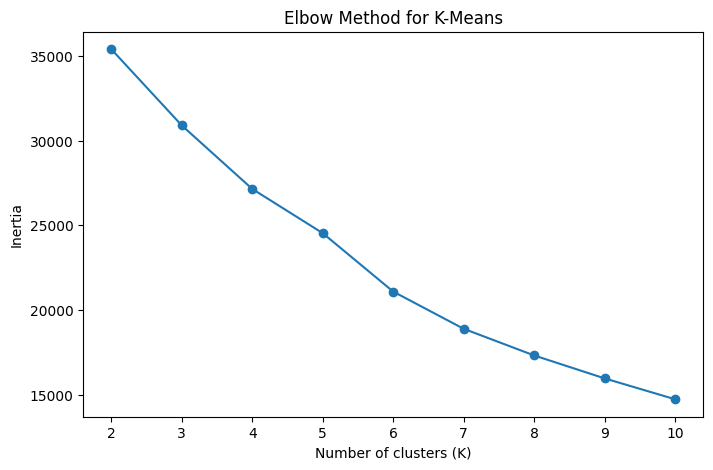

In [ ]:
inertias = []

for k in range(2, 11):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    model.fit(X)
    inertias.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(2, 11), inertias, marker='o')
plt.xlabel("Number of clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for K-Means")
plt.xticks(range(2, 11))
plt.show()

## Apply K-Means

- Fit K-Means with four clusters as the current example. If the elbow plot suggests another value, update `n_clusters` here and in the hierarchical clustering cell.

In [ ]:
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

kmeans_labels = kmeans.fit_predict(X)

print("Cluster sizes:")
print(pd.Series(kmeans_labels).value_counts().sort_index())

print(
    "Silhouette score:",
    round(silhouette_score(X, kmeans_labels), 3)
)

Cluster sizes:
0      15
1    2543
2    1273
3     168
Name: count, dtype: int64
Silhouette score: 0.309


## Describe K-Means clusters

- The table summarizes average feature values for each K-Means cluster, helping interpret how groups differ.

In [ ]:
data['KMeans_Cluster'] = kmeans_labels

print(
    data.groupby('KMeans_Cluster').mean().round(2)
)

                  Balance  Qual_miles  cc1_miles  cc2_miles  cc3_miles  \
KMeans_Cluster                                                           
0               138061.40       78.80       3.47       1.00       4.07   
1                43793.92       97.44       1.22       1.02       1.00   
2               116817.34      154.76       3.70       1.00       1.00   
3               191573.73      775.86       2.17       1.04       1.00   

                Bonus_miles  Bonus_trans  Flight_miles_12mo  Flight_trans_12  \
KMeans_Cluster                                                                 
0                  93927.87        28.07             506.67             1.60   
1                   4700.69         6.92             198.62             0.62   
2                  39216.20        18.76             334.36             1.00   
3                  31412.16        26.78            5365.67            15.64   

                Days_since_enroll  Award?  
KMeans_Cluster                

## Apply Agglomerative Clustering

- Agglomerative clustering builds groups by merging similar observations. Here, Ward linkage and four clusters are used.

In [ ]:
hierarchical = AgglomerativeClustering(
    n_clusters=4,
    linkage='ward'
)

hier_labels = hierarchical.fit_predict(X)

print("Cluster sizes:")
print(pd.Series(hier_labels).value_counts().sort_index())

print(
    "Silhouette score:",
    round(silhouette_score(X, hier_labels), 3)
)

Cluster sizes:
0    1380
1    2446
2     130
3      43
Name: count, dtype: int64
Silhouette score: 0.308


## Apply DBSCAN

- DBSCAN finds dense groups and marks outliers as `-1`. Results depend on `eps` and `min_samples`; inspect cluster counts before interpreting the score.

In [ ]:
dbscan = DBSCAN(eps=1.5, min_samples=5)
db_labels = dbscan.fit_predict(X)

print("Cluster labels and counts:")
print(pd.Series(db_labels).value_counts().sort_index())

print("Noise points:", np.sum(db_labels == -1))

valid = db_labels != -1
n_clusters = len(set(db_labels[valid]))

if n_clusters >= 2 and valid.sum() > n_clusters:
    print(
        "Silhouette score:",
        round(silhouette_score(X[valid], db_labels[valid]), 3)
    )
else:
    print("Silhouette score unavailable for these clusters.")

Cluster labels and counts:
-1     310
 0    2411
 1    1250
 2      15
 3       8
 4       5
Name: count, dtype: int64
Noise points: 310
Silhouette score: 0.294


## Visualize clusters with PCA

- PCA projects the scaled features into two dimensions for plotting. This view is a simplification of the full feature space.

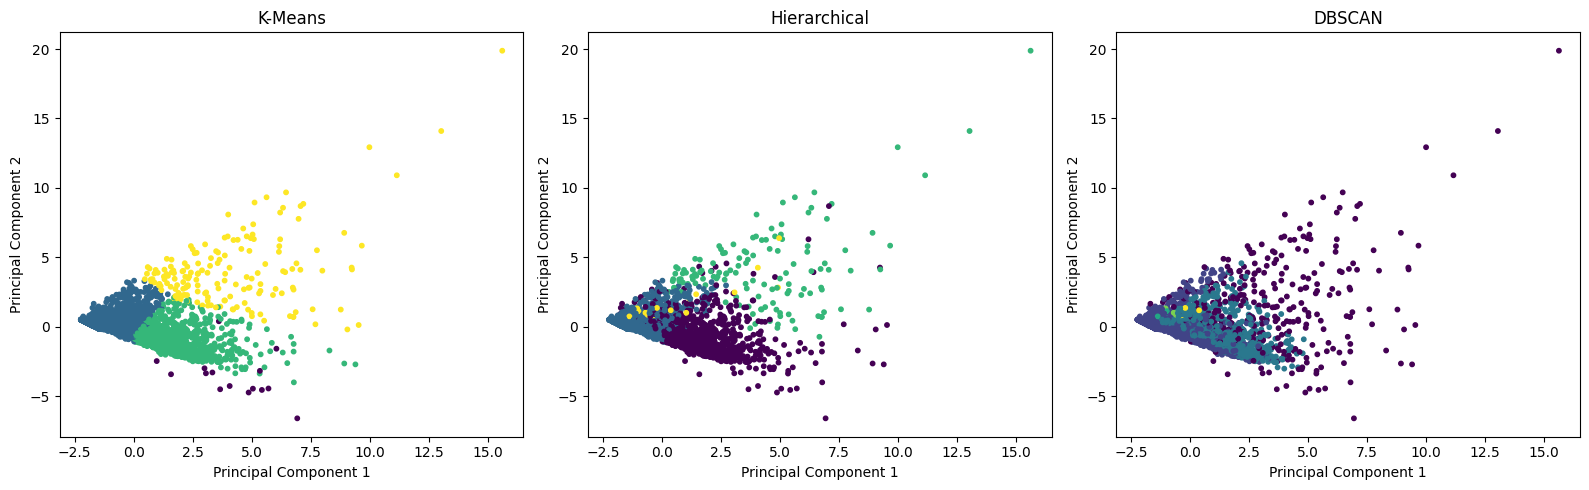

In [ ]:
pca = PCA(n_components=2)
X_2d = pca.fit_transform(X)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

labels_list = [
    (kmeans_labels, "K-Means"),
    (hier_labels, "Hierarchical"),
    (db_labels, "DBSCAN")
]

for ax, (labels, title) in zip(axes, labels_list):
    ax.scatter(
        X_2d[:, 0],
        X_2d[:, 1],
        c=labels,
        cmap='viridis',
        s=10
    )
    ax.set_title(title)
    ax.set_xlabel("Principal Component 1")
    ax.set_ylabel("Principal Component 2")

plt.tight_layout()
plt.show()

## Compare clustering algorithms

- Compare the number of clusters, noise points, and silhouette scores. Silhouette scores are not available for every clustering outcome.

In [ ]:
results = []

for name, labels in [
    ("K-Means", kmeans_labels),
    ("Hierarchical", hier_labels),
    ("DBSCAN", db_labels)
]:
    valid = labels != -1
    n_clusters = len(set(labels[valid]))
    score = np.nan

    if n_clusters >= 2 and valid.sum() > n_clusters:
        score = silhouette_score(X[valid], labels[valid])

    results.append({
        "Algorithm": name,
        "Clusters": n_clusters,
        "Noise points": int(np.sum(labels == -1)),
        "Silhouette score": score
    })

comparison = pd.DataFrame(results)
print(comparison.round(3))

      Algorithm  Clusters  Noise points  Silhouette score
0       K-Means         4             0             0.309
1  Hierarchical         4             0             0.308
2        DBSCAN         5           310             0.294


### Conclusion
This case study demonstrates how K-Means, Agglomerative Clustering, and DBSCAN can be used to explore customer groups in the EastWest Airlines dataset. The Elbow Method helps guide the choice of K, while silhouette scores and cluster summaries support comparison. The most useful model is the one that produces meaningful, interpretable customer segments for the dataset.